# AMP: Homework 5
**Author:** Ricardo Vega

# Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.special import assoc_legendre_p
from scipy.optimize import curve_fit
from scipy.special import voigt_profile
from scipy.stats import linregress

from sklearn.metrics import r2_score

import sympy as sp
from sympy.physics.hydrogen import Psi_nlm
from sympy.physics.hydrogen import R_nl

plt.rcParams.update({
    'axes.grid': True,
    'grid.alpha': 0.5,
    'grid.linestyle': '--',
    'axes.axisbelow': True,
    'font.size': 12
})

**Note:**  
I found this SymPy package above, `Psi_nlm`, that returns the 3D wavefunction is spherical coordinates. From my experience, it seems like it works very well and in a user-friendly way. Pretty much all you have to do is specify the spatial coordinates and the atomic number, then give it which $n,\ell,m$ values you want it to give you the wavefunction for. Pretty neat stuff.

# Problem 2

## Part B

In [2]:
# Defining variables in the wavefunction

r = sp.symbols('r', positive=True)
phi = sp.symbols('phi', real=True)
theta = sp.symbols('theta', real=True)
# Z = sp.symbols('Z', positive=True, integer=True, nonzero=True) # We are looking at hydrogen wavefunctions, so Z = 1 anyway
a_0 = sp.symbols('a_0')

In [3]:
# Setting up wavefunctions
n1_l0_m0 = Psi_nlm(1, 0, 0, r, phi, theta) # 1s
n3_l2_m0 = Psi_nlm(3, 2, 0, r, phi, theta) # 3d

# Use this to check for nonzero values
n2_l1_m0 = Psi_nlm(2, 1, 0, r, phi, theta) # 2p

jacobian = r**2 * sp.sin(theta)

# Integrands
## The wavefunctions returned by this sympy package are in Hartree atomic units, so we don't have to incorporate the Bohr radius explicitly when calculating
## the matrix elements
integrand_1s_1s = sp.conjugate(n1_l0_m0)* r*sp.cos(theta) * n1_l0_m0 * jacobian
integrand_3d_3d = sp.conjugate(n3_l2_m0)* r*sp.cos(theta) * n3_l2_m0 * jacobian

# Matrix element calculations
matrix_element_1s_1s = sp.integrate(
    integrand_1s_1s,
    (r, 0, sp.oo), (phi, 0, 2*sp.pi), (theta, 0, sp.pi)
    )
print('1s --> 1s transition matrix element:')
display(matrix_element_1s_1s)

matrix_element_3d_3d = sp.integrate(
    integrand_3d_3d,
    (r, 0, sp.oo), (phi, 0, 2*sp.pi), (theta, 0, sp.pi)
    )
print('3d --> 3d transition matrix element:')
display(matrix_element_3d_3d)

1s --> 1s transition matrix element:


0

3d --> 3d transition matrix element:


0

## Part C

In [4]:
# Defining constants and arrays

e = 1.602e-19               # [C]
a_0 = 5.29177210903e-11     # [m]
epsilon_0 = 8.854187817e-12 # [F/m]
h = 6.62607015e-34          # [J*s]
c = 3e8                     # [m/s]
m = 0                       # Quantum number

n_i = np.arange(1, 10, 1)
n_j = n_i + 1
print(f'''n_i array: {n_i}
n_j array: {n_j}''')

n_i array: [1 2 3 4 5 6 7 8 9]
n_j array: [ 2  3  4  5  6  7  8  9 10]


In [5]:
# Running a loop to calculate A_{ji} for n_j --> n_i transitions

A_ji_vals = np.array([])
transitions = []

for j, i in zip(n_j, n_i):

    t = '-'.join([str(j), str(i)])
    transitions.append(t)

    print(f'''n transition: {j} --> {i}
l transition: 1 --> 0''')

    wf_i = Psi_nlm(i, 0, m, r, phi, theta) # n_i s
    wf_j = Psi_nlm(j, 1, m, r, phi, theta) # n_j p

    integrand = sp.conjugate(wf_j) * r*sp.cos(theta) * wf_i * jacobian

    matrix_element = sp.integrate(
        integrand,
        (r, 0, sp.oo), (phi, 0, 2*sp.pi), (theta, 0, sp.pi)
        )
    matrix_element = matrix_element.evalf()

    delta_E = (-13.6 * (1/(j**2) - 1/(i**2))) * e # [J]
    nu = delta_E / h

    A_ji = ((16 * np.pi**3 * nu**3 * e**2 * a_0**2) / (3 * epsilon_0 * h * c**3)) * (sp.conjugate(matrix_element) * matrix_element)
    A_ji_vals = np.append(A_ji_vals, float(A_ji.evalf()))
    print(f'A_{j}-{i} = {A_ji:.2e}\n')

n transition: 2 --> 1
l transition: 1 --> 0
A_2-1 = 6.24e+8

n transition: 3 --> 2
l transition: 1 --> 0
A_3-2 = 2.24e+7

n transition: 4 --> 3
l transition: 1 --> 0
A_4-3 = 3.05e+6

n transition: 5 --> 4
l transition: 1 --> 0
A_5-4 = 7.35e+5

n transition: 6 --> 5
l transition: 1 --> 0
A_6-5 = 2.42e+5

n transition: 7 --> 6
l transition: 1 --> 0
A_7-6 = 9.76e+4

n transition: 8 --> 7
l transition: 1 --> 0
A_8-7 = 4.52e+4

n transition: 9 --> 8
l transition: 1 --> 0
A_9-8 = 2.32e+4

n transition: 10 --> 9
l transition: 1 --> 0
A_10-9 = 1.29e+4



## Part D

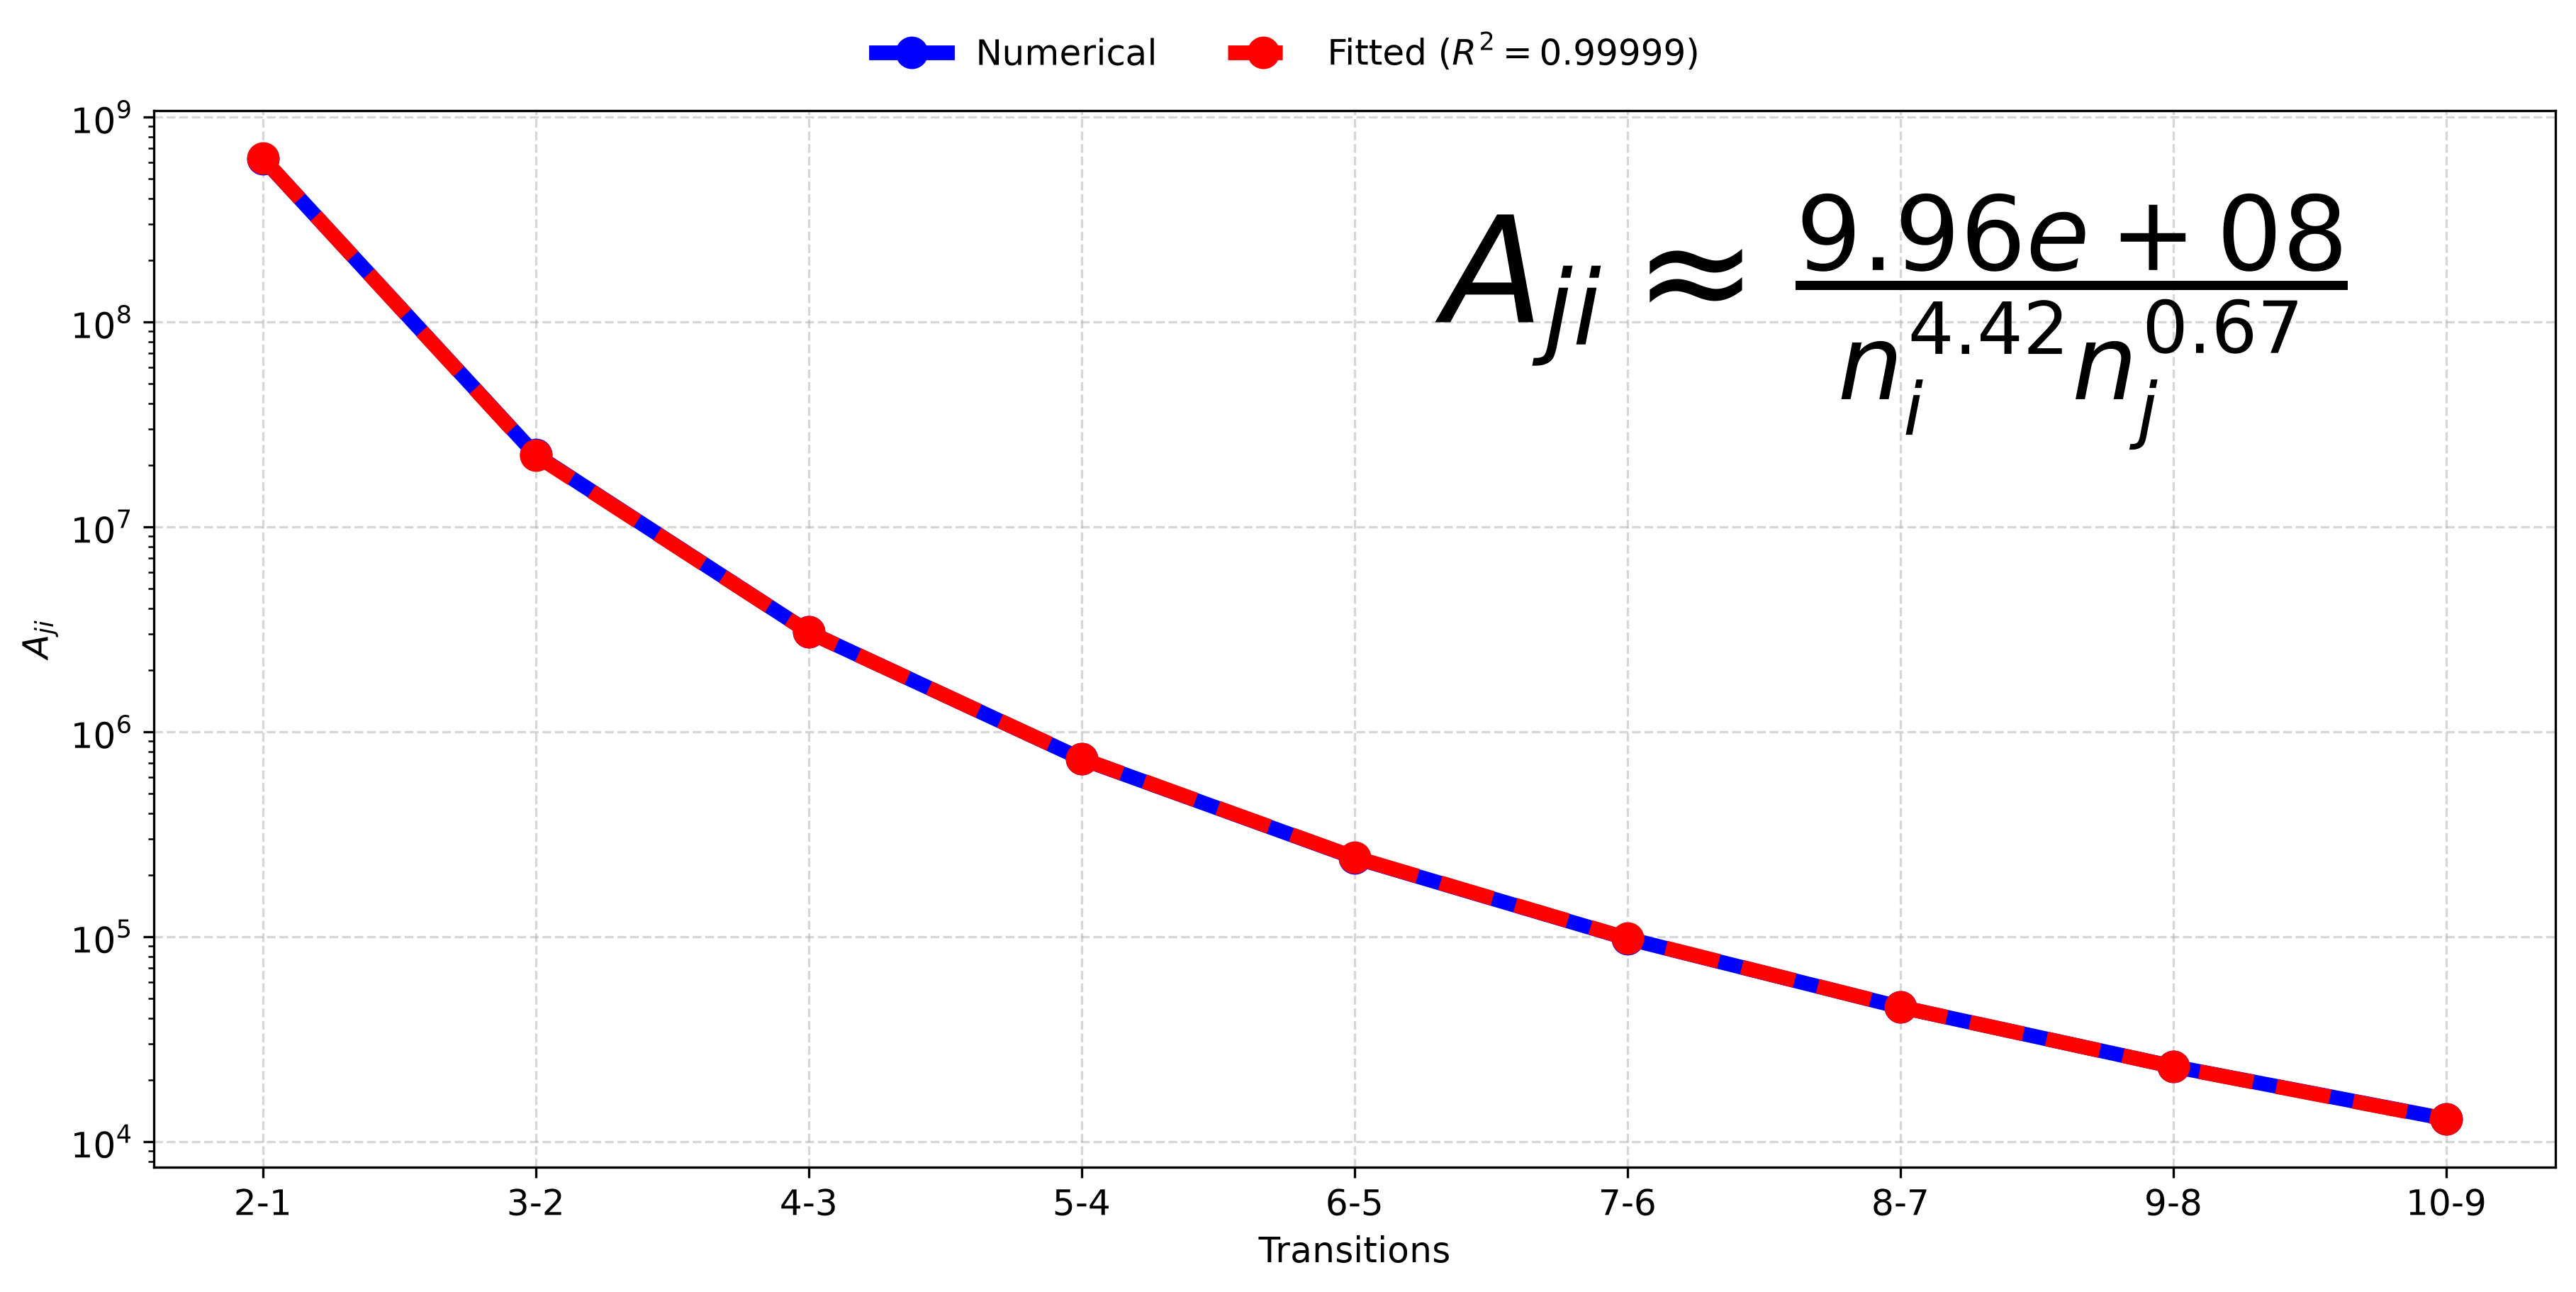

In [6]:
# Defining fitting model for approximation
def ln_model(N, ln_C, alpha, beta):
    n_i, n_j = N
    return ln_C - alpha*np.log(n_i) - beta*np.log(n_j)

# Fitting the model to the numerical data
param, cov = curve_fit(ln_model, (n_i, n_j), np.log(A_ji_vals))
ln_C, alpha, beta = param
C = np.exp(ln_C)
A_fitted = C / (n_i**alpha * n_j**beta)

# Calculating R^2 value
r_sq = r2_score(A_ji_vals, A_fitted)

fig, ax = plt.subplots(constrained_layout=True, figsize=(12,6), dpi=300)

ax.plot(transitions, A_ji_vals, 'bo-', ms=10, lw=5, label='Numerical')
ax.plot(transitions, A_fitted, 'ro--', ms=10, lw=5, label=f'Fitted ($R^2 = {r_sq:.5f}$)')

ax.text(x='8-7', y=1e8,
        s=f'$A_{{ji}} \\approx \\frac{{{C:.2e}}}{{n_i^{{{alpha:.2f}}} n_j^{{{beta:.2f}}}}}$',
        ha='center', va='center',
        fontsize=50)

ax.set(xlabel='Transitions', ylabel='$A_{ji}$', yscale='log')
fig.legend(loc='outside upper center', ncol=2, frameon=False)

# plt.savefig('amp_hw5_p2d.pdf')
plt.show()
plt.close()

# Problem 3

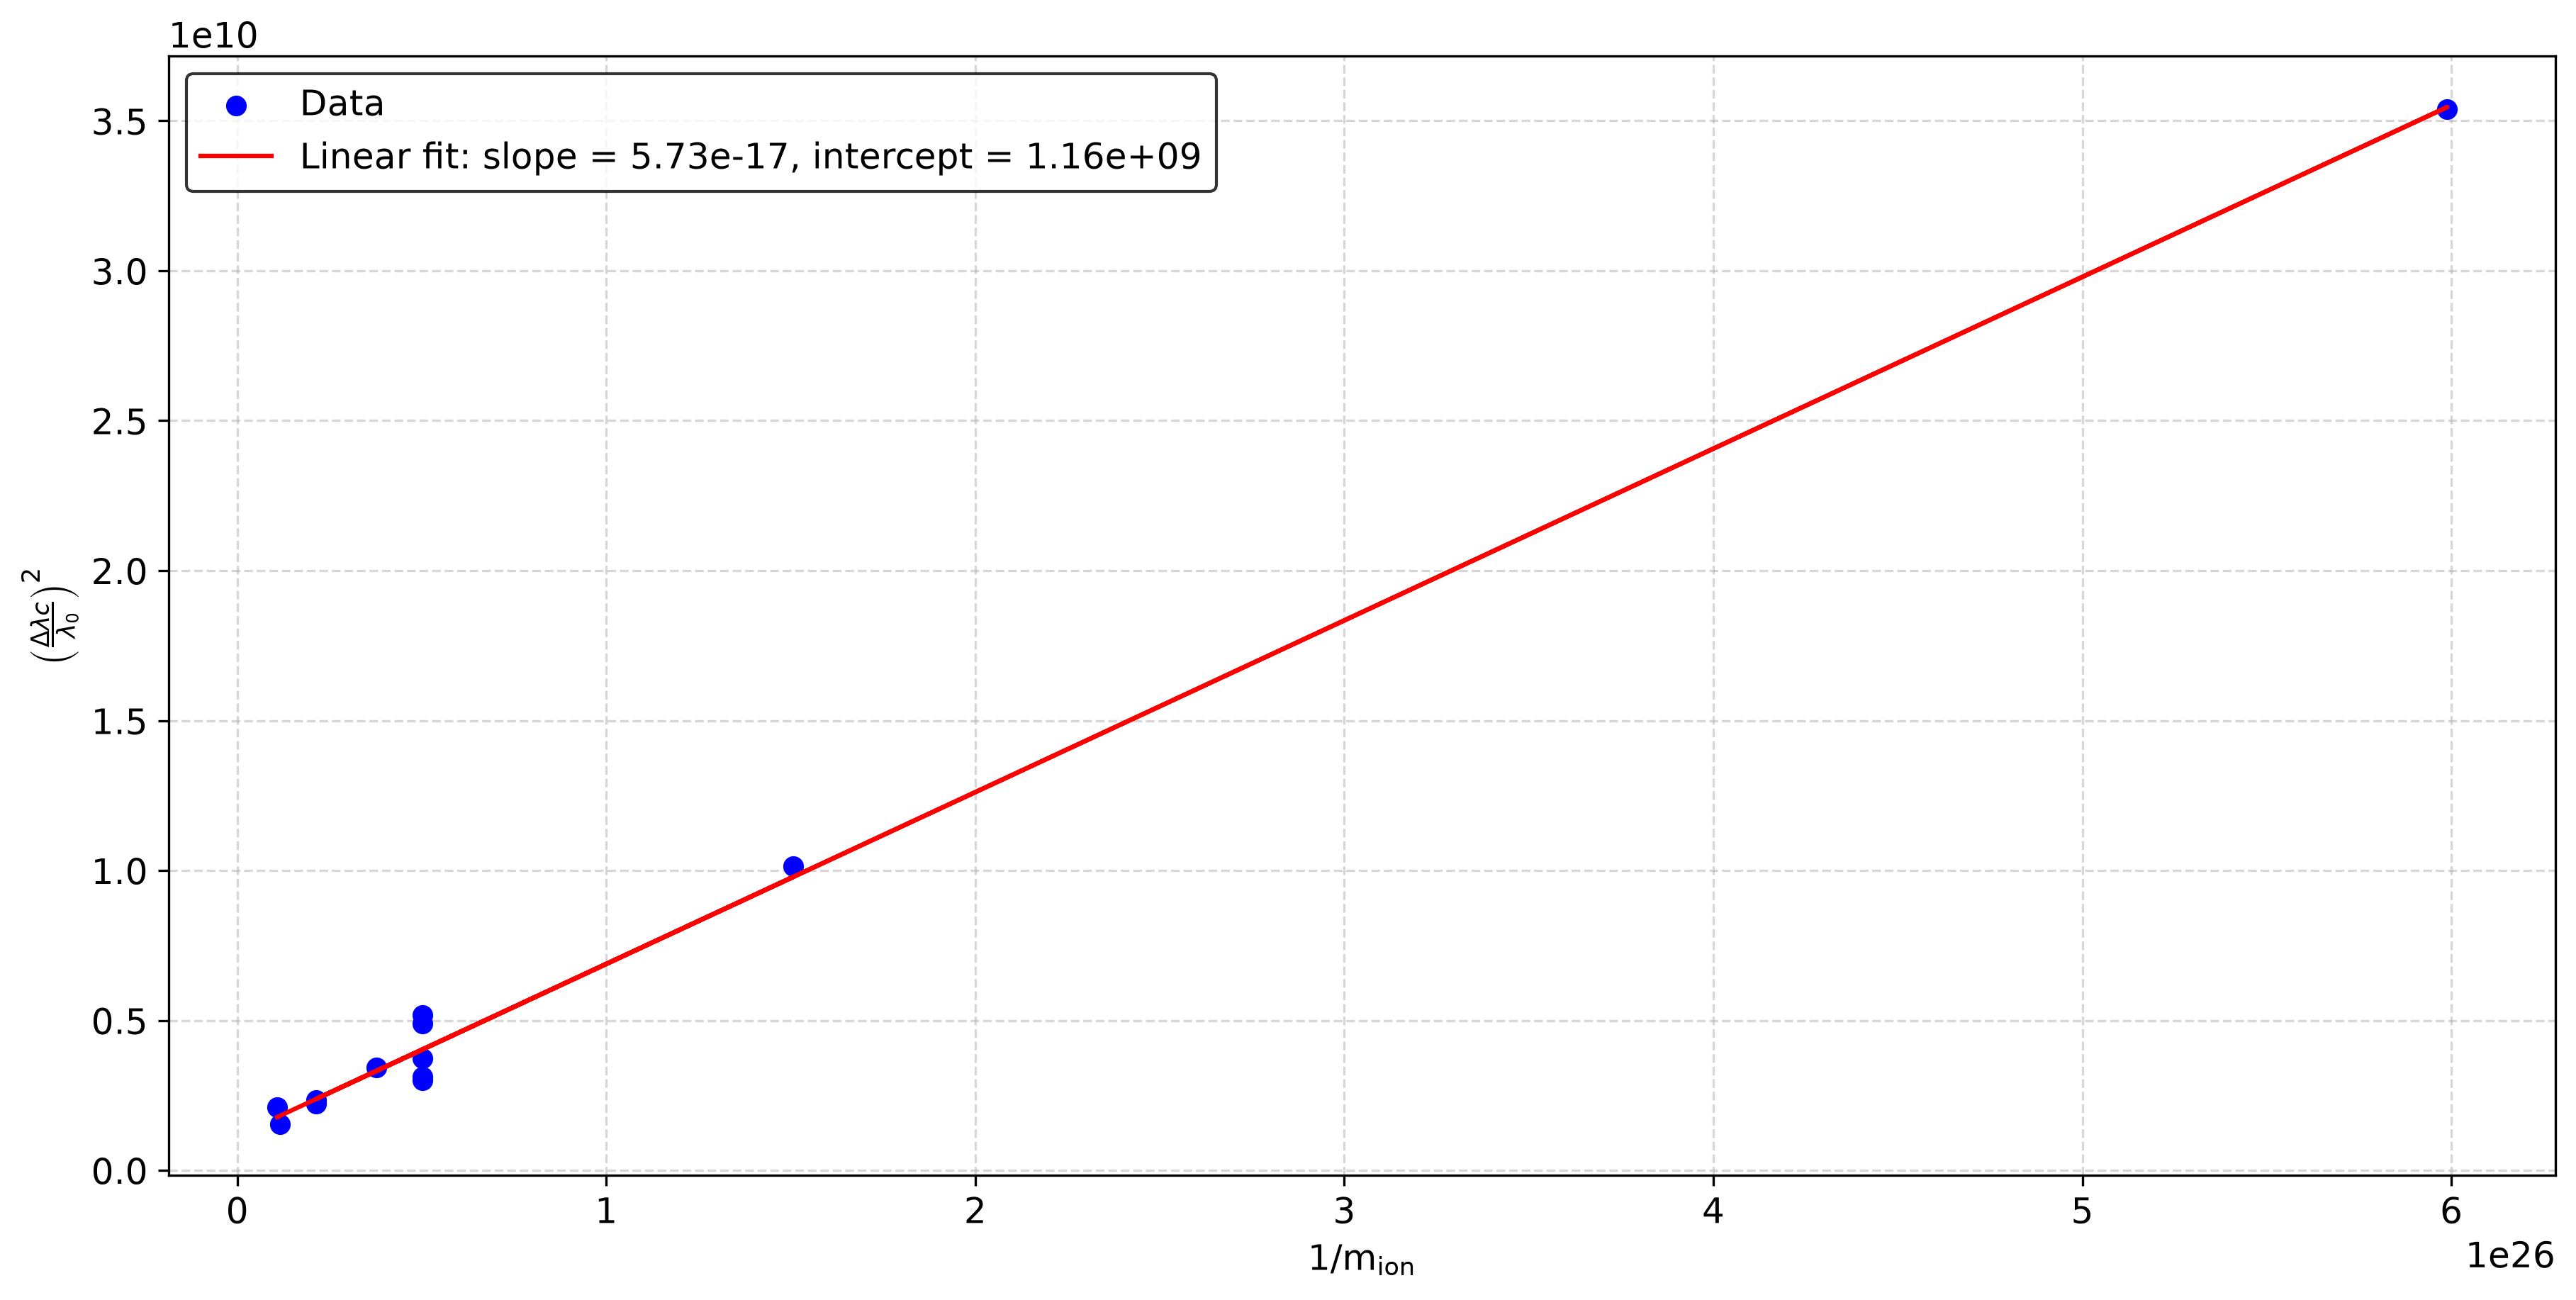

In [7]:
lambda_0 = np.array([977, 1032, 1175, 1216, 1335, 1394, 1548, 1640, 1808, 1909, 2056, 2175])                      # [Å]
fwhm = np.array([0.3898, 0.3355, 0.3647, 1.2696, 0.5181, 0.3747, 0.4711, 0.9163, 0.4731, 0.6477, 0.4461, 0.5537]) # [Å]
ions = ['C III', 'O VI', 'C III', 'H I', 'C II', 'Si IV', 'C IV', 'He II', 'Si II', 'C III', 'Cr II', 'Fe II']
c = 3e8                                                                                                           # [m/s]
k_B = 1.381e-23                                                                                                   # [J/K]
doppler_widths = fwhm / (2 * np.sqrt(np.log(2)))                                                                  # [Å]

masses = np.array([1.99e-26, 2.656e-26, 1.99e-26, 1.67e-27, 1.99e-26, 4.664e-26, 1.99e-26, 6.6423e-27, 4.664e-26, 1.99e-26, 8.634e-26, 9.27e-26]) # [kg]
m_e = 9.109e-31                                                                                                                                   # [kg]
ion_masses = np.array([
    masses[0]-(2*m_e),
    masses[1]-(5*m_e),
    masses[2]-(2*m_e),
    masses[3]-(0*m_e),
    masses[4]-(2*m_e),
    masses[5]-(3*m_e), # ==> all ion masses are also in [kg]
    masses[6]-(3*m_e),
    masses[7]-(1*m_e),
    masses[8]-(1*m_e),
    masses[9]-(2*m_e),
    masses[10]-(1*m_e),
    masses[11]-(1*m_e),
])

fig, ax = plt.subplots(constrained_layout=True, figsize=(12,6), dpi=300)

y = ((doppler_widths*c) / (lambda_0))**2
x = 1/ion_masses

linear_fit = linregress(x, y)
y_fit = linear_fit.slope * x + linear_fit.intercept

ax.scatter(x, y, c='b', label='Data')
ax.plot(x, y_fit, c='r', label=f'Linear fit: slope = {linear_fit.slope:.2e}, intercept = {linear_fit.intercept:.2e}')

ax.set(xlabel='1/m$_{\\text{ion}}$', ylabel='$\\left( \\frac{\\Delta \\lambda c}{\\lambda_0} \\right)^2$')
ax.legend(edgecolor='0')

plt.savefig('amp_hw5_p3.pdf')
plt.show()
plt.close()

In [8]:
T = linear_fit.slope / (2*k_B)
xi = np.sqrt(linear_fit.intercept)

print(f'''T = {T:.2e} K
Xi = {xi} m/s''')

T = 2.07e+06 K
Xi = 33990.072289537515 m/s
